# Esperimenti sul detector (Q3)

Il notebook fa girare **il vero `q3_detect.py`** fuori da Spark, sulla serie esportata, con parametri diversi.
Nessun container da riavviare e niente scritto su Kafka o Elasticsearch: ogni prova dura pochi secondi.

Requisiti nell'ambiente virtuale: `pip install pandas pyarrow matplotlib ipykernel`.
Imposta qui sotto il percorso della cartella `spark/jobs` del repository.

In [17]:
from pathlib import Path
REPO_JOBS = Path("../spark/jobs").expanduser()   # <-- cartella che contiene q3_detect.py
SERIE = Path("dati/sentiment_1m.parquet")
assert (REPO_JOBS / "q3_detect.py").exists(), f"q3_detect.py non trovato in {REPO_JOBS}"

## 1. Caricare il detector fuori da Spark

`q3_detect.py` importa pyspark e legge alcune variabili d'ambiente di Kafka, ma la funzione `detect` usa solo Python e pandas.
Se pyspark non è installato, al suo posto mettiamo dei moduli finti che bastano per l'import.
I parametri del detector si leggono da `DET_*` all'import, quindi per cambiarli si impostano le variabili e si ricarica il modulo.

In [18]:
import importlib, json, math, os, sys, types
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def _pyspark_finto():
    class _Qualsiasi:
        def __init__(self, *a, **k): pass
        def __getattr__(self, nome): return _Qualsiasi()
        def __call__(self, *a, **k): return _Qualsiasi()
    class StructField:
        def __init__(self, name, *a, **k): self.name = name
    class StructType:
        def __init__(self, fields=()): self.fields = list(fields)
    moduli = {n: types.ModuleType(n) for n in
              ["pyspark", "pyspark.sql", "pyspark.sql.functions", "pyspark.sql.streaming",
               "pyspark.sql.streaming.state", "pyspark.sql.types"]}
    moduli["pyspark.sql"].SparkSession = _Qualsiasi
    moduli["pyspark.sql"].functions = moduli["pyspark.sql.functions"]
    moduli["pyspark.sql.streaming.state"].GroupState = object
    moduli["pyspark.sql.streaming.state"].GroupStateTimeout = _Qualsiasi()
    t = moduli["pyspark.sql.types"]
    t.StructField, t.StructType = StructField, StructType
    for nome in ["BooleanType", "DoubleType", "LongType", "StringType"]:
        setattr(t, nome, _Qualsiasi)
    sys.modules.update(moduli)

try:
    import pyspark.sql.types  # noqa: F401
except ImportError:
    _pyspark_finto()

# Variabili richieste all'import ma non usate da detect
for v in ["KAFKA_BOOTSTRAP_SERVERS", "CHECKPOINT_ROOT", "Q3_INPUT_TOPIC", "Q3_MONITOR_TOPIC",
          "Q3_ALERTS_TOPIC", "Q3_STARTING_OFFSETS", "Q3_MAX_OFFSETS_PER_TRIGGER",
          "Q3_TRIGGER_INTERVAL", "Q3_SHUFFLE_PARTITIONS"]:
    os.environ.setdefault(v, "offline")
sys.path.insert(0, str(REPO_JOBS))

NOMI_ENV = {"alpha": "DET_ALPHA", "k": "DET_K", "k_low": "DET_K_LOW", "k_vol": "DET_K_VOL",
            "clip_k": "DET_CLIP_K", "sigma_min_sentiment": "DET_SIGMA_MIN_SENT",
            "sigma_min_volume": "DET_SIGMA_MIN_VOL", "min_posts": "DET_MIN_POSTS",
            "min_authors": "DET_MIN_AUTHORS", "r_min": "DET_R_MIN", "partial_ratio": "DET_PARTIAL_RATIO",
            "warmup_n": "DET_WARMUP_N", "close_after": "DET_CLOSE_AFTER",
            "gap_reset_minutes": "DET_GAP_RESET_MINUTES"}

def carica_detector(**params):
    """Ricarica q3_detect con i parametri dati; quelli non indicati restano ai valori del codice."""
    for env in NOMI_ENV.values():
        os.environ.pop(env, None)
    for nome, valore in params.items():
        os.environ[NOMI_ENV[nome]] = str(valore)
    import q3_detect
    return importlib.reload(q3_detect)

class StatoFinto:
    """Fa le veci del GroupState di Spark: parte vuoto e conserva l'ultimo stato."""
    exists, get = False, None
    def update(self, valori): self.exists, self.get = True, valori

def esegui(ingresso, **params):
    """Fa girare detect sulla serie in un solo batch. Restituisce (monitor, alert)."""
    q3 = carica_detector(**params)
    righe = []
    for modello, gruppo in ingresso.groupby("model"):
        for out in q3.detect((modello,), iter([gruppo]), StatoFinto()):
            righe.append(out)
    out = pd.concat(righe, ignore_index=True)
    monitor = pd.DataFrame([json.loads(v) for v in out[out.kind == "monitor"].value])
    alert = pd.DataFrame([json.loads(v) for v in out[out.kind == "alert"].value])
    return monitor, alert

print("Parametri attuali nel codice:", carica_detector().PARAMS)

Parametri attuali nel codice: {'alpha': 0.03, 'k': 3.5, 'k_low': 2.5, 'k_vol': 4.0, 'clip_k': 3.5, 'sigma_min_sentiment': 0.01, 'sigma_min_volume': 0.05, 'min_posts': 300, 'min_authors': 250, 'r_min': 0.8, 'partial_ratio': 0.5, 'warmup_n': 40, 'close_after': 5, 'gap_reset_minutes': 60.0}


## 2. Ricostruire l'ingresso di Q3

Q3 legge `sentiment.1m`, cioè i campi di Q2. Li riprendiamo dalla serie esportata, con gli orari di nuovo in formato ISO, come arrivano da Kafka.

In [19]:
serie = pd.read_parquet(SERIE).sort_values("window_start").reset_index(drop=True)
CAMPI_Q2 = ["window_start", "window_end", "n_posts", "n_authors", "mean_sentiment",
            "std_sentiment", "share_negative", "share_positive", "model"]
ingresso = serie[CAMPI_Q2].copy()
for c in ["window_start", "window_end"]:
    ingresso[c] = ingresso[c].dt.strftime("%Y-%m-%dT%H:%M:%SZ")
print(f"{len(ingresso)} finestre, da {ingresso.window_start.iloc[0]} a {ingresso.window_start.iloc[-1]}")

350 finestre, da 2026-11-08T16:57:00Z a 2026-11-08T22:46:00Z


## 3. Verifica: il banco di prova riproduce Q3?

Con i parametri attuali, il risultato offline deve coincidere con quello che Q3 ha scritto in `sentiment-1m`.
Se le differenze sono zero (o dell'ordine di 1e-12), gli esperimenti successivi sono affidabili.

In [20]:
mon, al = esegui(ingresso)
assert len(mon) == len(serie), "numero di finestre diverso"
for c in ["baseline_mean", "baseline_std", "z_sentiment", "z_volume", "baseline_volume"]:
    diff = (mon[c].astype(float) - serie[c].astype(float)).abs().max()
    print(f"{c:16s} differenza massima: {diff:.2e}")
for c in ["is_shock", "volume_spike", "warmup"]:
    print(f"{c:16s} finestre diverse: {(mon[c].values != serie[c].values).sum()}")
print(f"{'skip_reason':16s} finestre diverse: {(mon.skip_reason.fillna('-').values != serie.skip_reason.fillna('-').values).sum()}")
print(f"Alert offline: {len(al)}")

baseline_mean    differenza massima: 0.00e+00
baseline_std     differenza massima: 0.00e+00
z_sentiment      differenza massima: 0.00e+00
z_volume         differenza massima: 0.00e+00
baseline_volume  differenza massima: 0.00e+00
is_shock         finestre diverse: 0
volume_spike     finestre diverse: 0
warmup           finestre diverse: 0
skip_reason      finestre diverse: 0
Alert offline: 0


## 4. Prova 1: shock sintetici sulla serie vera

In tanti punti diversi della serata (dopo il warmup) spostiamo il sentiment medio di una quantità `delta` per `durata` minuti,
e vediamo se il detector apre un episodio in quell'intervallo e con quale ritardo. Ogni prova contiene un solo shock, su una copia della serie.

Due scenari: **solo sentiment** (vale solo la regola forte, `k`) e **sentiment + volume ×1,5** (può scattare anche la regola moderata, `k_low` con `k_vol`).
Per riferimento, la deviazione tipica della baseline nella serata è stampata qui sotto: uno shock di `delta` vale circa `delta / σ` deviazioni standard.

In [21]:
sigma_tipica = serie.loc[~serie.warmup, "baseline_std"].median()
print(f"Deviazione tipica della baseline (mediana dopo il warmup): {sigma_tipica:.4f}")

def inietta(ingresso, inizio, durata, delta, fattore_volume=1.0, rampa=0):
    """Copia della serie con uno shock dalla finestra `inizio` per `durata` finestre.
    Con rampa > 0 lo spostamento cresce linearmente nelle prime `rampa` finestre (shock graduale)."""
    df = ingresso.copy()
    for i in range(durata):
        j = inizio + i
        if j >= len(df):
            break
        quota = min(1.0, (i + 1) / rampa) if rampa else 1.0
        df.loc[j, "mean_sentiment"] += delta * quota
        if fattore_volume != 1.0:
            for c in ["n_posts", "n_authors"]:
                df.loc[j, c] = int(round(df.loc[j, c] * (1 + (fattore_volume - 1) * quota)))
    return df

def posizioni(durata, n=30, warmup_n=40):
    prima = warmup_n + 20               # dopo il warmup, con un po' di margine
    ultima = len(ingresso) - durata - 6
    return np.linspace(prima, ultima, n).astype(int)

def prova(delta, durata=5, fattore_volume=1.0, rampa=0, n_posizioni=30, **params):
    """Percentuale di shock rilevati e ritardo mediano (minuti dall'inizio dello shock)."""
    rilevati, ritardi = 0, []
    for p in posizioni(durata, n_posizioni, int(params.get("warmup_n", 40))):
        mon, _ = esegui(inietta(ingresso, p, durata, delta, fattore_volume, rampa), **params)
        # Rilevato se almeno una finestra dello shock e' giudicata anomala. Guardiamo il monitor e non
        # solo le aperture, cosi' conta anche uno shock che cade dentro un episodio gia' aperto.
        shock = mon.iloc[p:p + durata]
        shock = shock[shock.is_shock]
        if len(shock):
            rilevati += 1
            ritardi.append((pd.Timestamp(shock.window_start.iloc[0])
                            - pd.Timestamp(ingresso.window_start[p])).total_seconds() / 60)
    return rilevati / n_posizioni, (np.median(ritardi) if ritardi else np.nan)

Deviazione tipica della baseline (mediana dopo il warmup): 0.0165


scenario,"sentiment + volume ×1,5",solo sentiment
delta,,
-0.100000,100%,100%
-0.080000,100%,100%
-0.060000,100%,83%
-0.050000,100%,60%
-0.040000,87%,43%
-0.030000,67%,23%
-0.020000,37%,7%


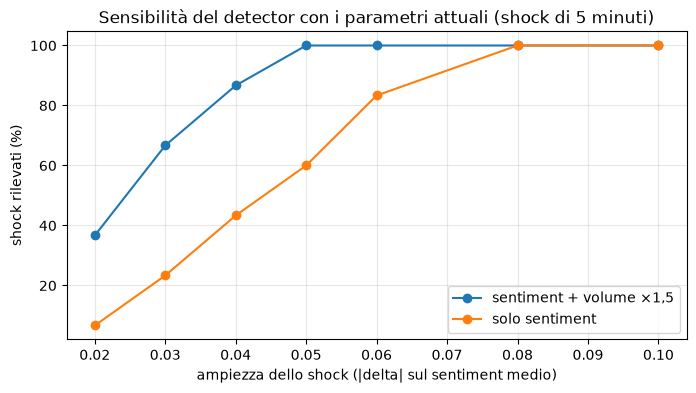

In [22]:
DELTA = [-0.02, -0.03, -0.04, -0.05, -0.06, -0.08, -0.10]
risultati = []
for scenario, fv in [("solo sentiment", 1.0), ("sentiment + volume ×1,5", 1.5)]:
    for d in DELTA:
        quota, ritardo = prova(d, fattore_volume=fv)
        risultati.append({"scenario": scenario, "delta": d, "delta_in_sigma": abs(d) / sigma_tipica,
                          "rilevati": quota, "ritardo_min": ritardo})
prova1 = pd.DataFrame(risultati)
display(prova1.pivot(index="delta", columns="scenario", values="rilevati").style.format("{:.0%}"))

fig, ax = plt.subplots(figsize=(8, 4))
for scenario, g in prova1.groupby("scenario"):
    ax.plot(g.delta.abs(), g.rilevati * 100, marker="o", label=scenario)
ax.set_xlabel("ampiezza dello shock (|delta| sul sentiment medio)")
ax.set_ylabel("shock rilevati (%)"); ax.grid(alpha=0.3); ax.legend()
ax.set_title("Sensibilità del detector con i parametri attuali (shock di 5 minuti)")
plt.show()

Lo stesso confronto con soglie diverse: per esempio `k` = 3 al posto di 3,5. Prima di abbassare una soglia,
guarda anche quante finestre della serata *senza* shock iniettati la supererebbero (falsi allarmi), stampate in fondo.

In [23]:
VARIANTI = {"attuale (k=3,5)": {}, "k=3": {"k": 3.0, "clip_k": 3.0}, "k=4": {"k": 4.0, "clip_k": 4.0}}
righe = []
for nome, params in VARIANTI.items():
    for d in DELTA:
        quota, _ = prova(d, **params)
        righe.append({"variante": nome, "delta": d, "rilevati": quota})
    _, al_reale = esegui(ingresso, **params)
    n_falsi = 0 if al_reale.empty else (al_reale.status == "open").sum()
    print(f"{nome:16s} episodi sulla serata reale (senza iniezioni): {n_falsi}")
confronto_k = pd.DataFrame(righe)
display(confronto_k.pivot(index="delta", columns="variante", values="rilevati").style.format("{:.0%}"))

attuale (k=3,5)  episodi sulla serata reale (senza iniezioni): 0
k=3              episodi sulla serata reale (senza iniezioni): 2
k=4              episodi sulla serata reale (senza iniezioni): 0


variante,"attuale (k=3,5)",k=3,k=4
delta,,,
-0.100000,100%,100%,100%
-0.080000,100%,100%,97%
-0.060000,83%,100%,53%
-0.050000,60%,87%,40%
-0.040000,43%,60%,27%
-0.030000,23%,40%,7%
-0.020000,7%,20%,3%


Nota: `clip_k` nel codice vale per default quanto `k`. Cambiando `k` da ambiente, `clip_k` resta 3,5 se non lo si imposta,
per questo nelle varianti lo cambiamo insieme, come farebbe il codice.

## 5. Prova 2: il peso di `alpha`

Confrontiamo tre velocità della baseline su due tipi di shock: improvviso (5 minuti) e **graduale**
(lo spostamento cresce in 20 minuti e poi resta per altri 10). Una baseline veloce dovrebbe perdere gli shock graduali.
Il warmup va scalato con `alpha` (deve restare sopra `1/alpha`), come spiegato nel documento di Q3.

In [24]:
ALPHAS = [0.015, 0.03, 0.05]
def params_alpha(a):
    return {"alpha": a, "warmup_n": max(40, math.ceil(1.2 / a))}

righe = []
for a in ALPHAS:
    p = params_alpha(a)
    mon_a, al_a = esegui(ingresso, **p)
    attive = mon_a[mon_a.skip_reason.isna() & ~mon_a.warmup & mon_a.z_sentiment.notna()]
    for d in [-0.04, -0.06, -0.08]:
        q_imp, r_imp = prova(d, durata=5, **p)
        q_grad, r_grad = prova(d, durata=30, rampa=20, **p)
        righe.append({"alpha": a, "delta": d, "improvviso": q_imp, "graduale": q_grad,
                      "ritardo_graduale_min": r_grad})
    print(f"alpha={a}: warmup {p['warmup_n']}, finestre attive {len(attive)}, "
          f"dev. std di z sulla serata {attive.z_sentiment.std():.2f}, "
          f"episodi senza iniezioni {0 if al_a.empty else (al_a.status == 'open').sum()}")
prova2 = pd.DataFrame(righe)
display(prova2.style.format({"improvviso": "{:.0%}", "graduale": "{:.0%}", "ritardo_graduale_min": "{:.1f}"}))

alpha=0.015: warmup 80, finestre attive 269, dev. std di z sulla serata 1.00, episodi senza iniezioni 0
alpha=0.03: warmup 40, finestre attive 309, dev. std di z sulla serata 1.02, episodi senza iniezioni 0
alpha=0.05: warmup 40, finestre attive 309, dev. std di z sulla serata 1.04, episodi senza iniezioni 0


,alpha,delta,improvviso,graduale,ritardo_graduale_min
0,0.015000,-0.040000,37%,23%,15.0
1,0.015000,-0.060000,93%,33%,14.5
2,0.015000,-0.080000,100%,67%,13.0
3,0.030000,-0.040000,43%,17%,12.0
4,0.030000,-0.060000,83%,30%,11.0
5,0.030000,-0.080000,100%,33%,10.5
6,0.050000,-0.040000,43%,13%,13.0
7,0.050000,-0.060000,83%,13%,10.5
8,0.050000,-0.080000,100%,20%,8.0


Attenzione con `alpha` = 0,015: il warmup sale a 80 finestre e la serata ne ha circa 350, quindi le posizioni utili per gli shock si riducono
e la prima parte della serie non è ancora a regime. I risultati diventano più solidi con sessioni più lunghe.

## 6. Prova 3: il comportamento durante e dopo uno shock

### 6.1 Uno shock di 10 minuti produce un solo episodio, con i confini giusti?

Inseriamo uno shock di 10 minuti in 20 punti della serata e, per ognuno, guardiamo l'episodio che ne esce:
quanti episodi si aprono, se l'inizio coincide con la prima finestra dello shock, se la fine coincide con l'ultima,
come si chiude e dopo quanto. Due ampiezze: −0,06 e −0,10.

Il documento di Q3 (§7.2) prevede che, durante uno shock prolungato, la baseline si allarghi e lo assorba in qualche minuto:
se succede, l'episodio finisce *prima* della fine vera dello shock.

In [25]:
DURATA_EP = 10
OSSERVA = 40                         # minuti osservati dall'inizio dello shock

def analizza_episodio(delta, p):
    mon, al = esegui(inietta(ingresso, p, DURATA_EP, delta))
    t0 = pd.Timestamp(ingresso.window_start[p])
    fine_vera = pd.Timestamp(ingresso.window_end[p + DURATA_EP - 1])
    limite = pd.Timestamp(ingresso.window_start[p + OSSERVA])
    r = {"delta": delta, "posizione": p, "episodi": 0}
    if al.empty:
        return r
    al = al.assign(t=pd.to_datetime(al.start))
    aperti = al[(al.status == "open") & (al.t >= t0) & (al.t < limite)]
    r["episodi"] = len(aperti)
    if not len(aperti):
        return r
    ep = aperti.iloc[0].alert_id
    chiuso = al[(al.alert_id == ep) & (al.status == "closed")]
    finestre_ep = mon[mon.alert_id == ep]
    r.update({
        "inizio_min": (pd.Timestamp(aperti.iloc[0].start) - t0).total_seconds() / 60,
        "peak_z": aperti.iloc[0].peak_z if chiuso.empty else chiuso.iloc[0].peak_z,
    })
    if len(chiuso):
        c = chiuso.iloc[0]
        r.update({
            "fine_rispetto_vera_min": (pd.Timestamp(c.end) - fine_vera).total_seconds() / 60,
            "finestre_anomale": c.n_shock_windows,
            "chiusura": c.close_reason,
            "durata_episodio_min": len(finestre_ep),
        })
    else:
        r["chiusura"] = "ancora aperto"
    return r

pos_ep = np.linspace(60, len(ingresso) - OSSERVA - 2, 20).astype(int)
episodi = pd.DataFrame([analizza_episodio(d, p) for d in [-0.06, -0.10] for p in pos_ep])

for d, g in episodi.groupby("delta"):
    print(f"\n=== Shock di {d} per {DURATA_EP} minuti ({len(g)} posizioni)")
    print(f"Episodi aperti: {g.episodi.value_counts().sort_index().to_dict()}  (numero di episodi: quante volte)")
    v = g[g.episodi >= 1]
    if len(v):
        print(f"Inizio rispetto allo shock (min): {v.inizio_min.value_counts().sort_index().to_dict()}")
        print(f"Finestre anomale nell'episodio: mediana {v.finestre_anomale.median():.0f} su {DURATA_EP}, "
              f"min {v.finestre_anomale.min():.0f}, max {v.finestre_anomale.max():.0f}")
        print(f"Fine rispetto alla fine vera (min, negativo = prima): mediana {v.fine_rispetto_vera_min.median():.0f}, "
              f"min {v.fine_rispetto_vera_min.min():.0f}, max {v.fine_rispetto_vera_min.max():.0f}")
        print(f"Motivo di chiusura: {v.chiusura.value_counts().to_dict()}")
        print(f"Durata dell'episodio fino alla chiusura (min): mediana {v.durata_episodio_min.median():.0f}")
        print(f"Picco di z: mediana {v.peak_z.median():.1f}")


=== Shock di -0.1 per 10 minuti (20 posizioni)
Episodi aperti: {1: 20}  (numero di episodi: quante volte)
Inizio rispetto allo shock (min): {0.0: 20}
Finestre anomale nell'episodio: mediana 4 su 10, min 3, max 5
Fine rispetto alla fine vera (min, negativo = prima): mediana -6, min -7, max -1
Motivo di chiusura: {'normal': 20}
Durata dell'episodio fino alla chiusura (min): mediana 9
Picco di z: mediana -6.4

=== Shock di -0.06 per 10 minuti (20 posizioni)
Episodi aperti: {0: 3, 1: 17}  (numero di episodi: quante volte)
Inizio rispetto allo shock (min): {0.0: 13, 1.0: 3, 4.0: 1}
Finestre anomale nell'episodio: mediana 1 su 10, min 1, max 3
Fine rispetto alla fine vera (min, negativo = prima): mediana -8, min -9, max -1
Motivo di chiusura: {'normal': 17}
Durata dell'episodio fino alla chiusura (min): mediana 6
Picco di z: mediana -4.3


Un esempio nel dettaglio: la baseline e la sua banda durante e dopo lo shock di −0,10.

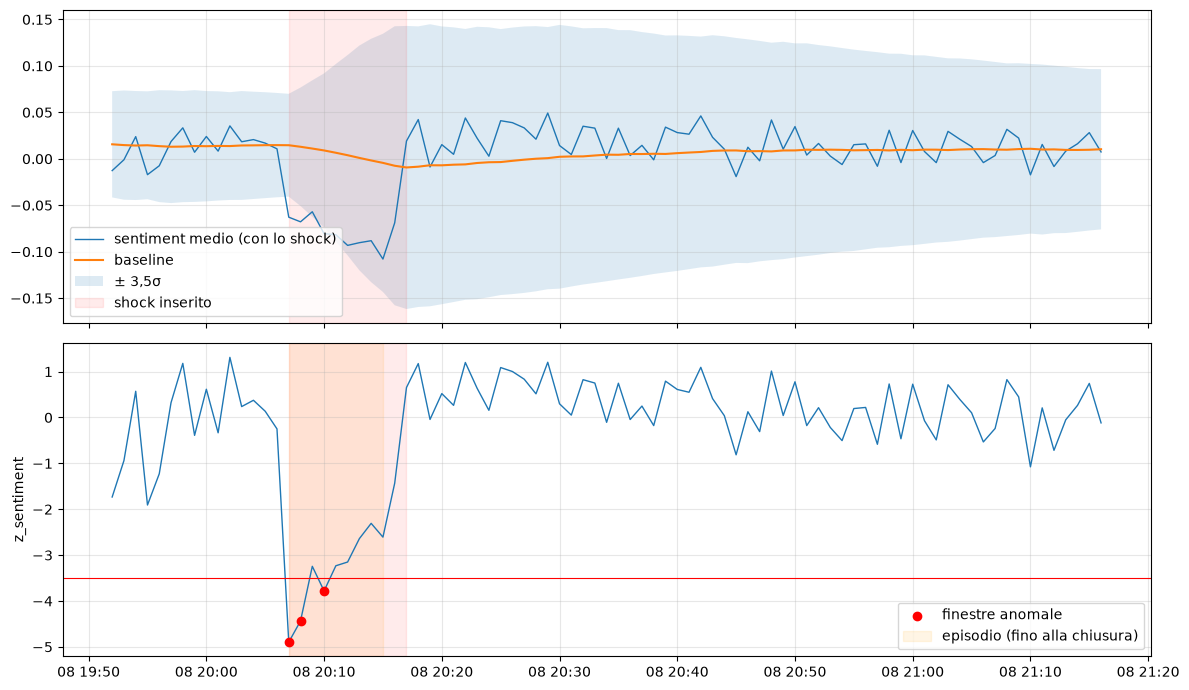

,alert_id,status,start,direction,peak_z,peak_window,peak_mean_sentiment,baseline_mean,baseline_std,peak_n_posts,z_volume,n_shock_windows,model,params,end,close_reason
0,shock-2026-11-08T20:07:00Z,open,2026-11-08T20:07:00Z,negative,-4.896788,2026-11-08T20:07:00Z,-0.06283,0.014609,0.015814,1796,0.222988,1,cardiffnlp/twitter-roberta-base-sentiment-late...,"{'alpha': 0.03, 'k': 3.5, 'k_low': 2.5, 'k_vol...",NaN,NaN
1,shock-2026-11-08T20:07:00Z,closed,2026-11-08T20:07:00Z,negative,-4.896788,2026-11-08T20:07:00Z,-0.06283,0.014609,0.015814,1796,0.222988,3,cardiffnlp/twitter-roberta-base-sentiment-late...,"{'alpha': 0.03, 'k': 3.5, 'k_low': 2.5, 'k_vol...",2026-11-08T20:11:00Z,normal


In [26]:
p = int(pos_ep[len(pos_ep) // 2])
mon_es, al_es = esegui(inietta(ingresso, p, DURATA_EP, -0.10))
finestra = mon_es.iloc[p - 15:p + 70].copy()
finestra["t"] = pd.to_datetime(finestra.window_start)
t0, t1 = finestra.t.iloc[15], finestra.t.iloc[15 + DURATA_EP]

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
ax = axes[0]
ax.plot(finestra.t, finestra.mean_sentiment, lw=1, label="sentiment medio (con lo shock)")
ax.plot(finestra.t, finestra.baseline_mean, lw=1.5, label="baseline")
ax.fill_between(finestra.t, finestra.baseline_mean - 3.5 * finestra.baseline_std,
                finestra.baseline_mean + 3.5 * finestra.baseline_std, alpha=0.15, label="± 3,5σ")
ax.axvspan(t0, t1, color="red", alpha=0.08, label="shock inserito")
ax.legend(); ax.grid(alpha=0.3)
ax = axes[1]
ax.plot(finestra.t, finestra.z_sentiment, lw=1)
anom = finestra[finestra.is_shock]
ax.scatter(anom.t, anom.z_sentiment, c="red", zorder=3, label="finestre anomale")
ep = finestra[finestra.alert_id.notna()]
if len(ep):
    ax.axvspan(ep.t.min(), ep.t.max(), color="orange", alpha=0.1, label="episodio (fino alla chiusura)")
ax.axhline(-3.5, c="red", lw=0.8); ax.axvspan(t0, t1, color="red", alpha=0.08)
ax.set_ylabel("z_sentiment"); ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()
display(al_es)

### 6.2 Dopo uno shock, il detector vede ancora il successivo?

Il documento di Q3 (§7.3) calcola che dopo uno shock la variabilità della baseline resta gonfiata per circa un'ora,
quindi un secondo shock uguale produce uno z-score più piccolo. Qui lo misuriamo sul rumore reale: due shock uguali di 5 minuti,
con 20, 40, 60, 90 e 120 minuti tra l'inizio del primo e l'inizio del secondo. Come riferimento,
lo stesso secondo shock viene provato anche da solo, nelle stesse posizioni.

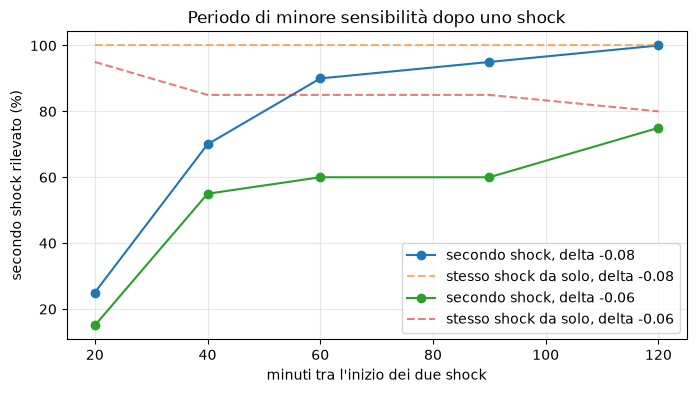

In [27]:
DISTANZE = [20, 40, 60, 90, 120]
def visto(mon, p, durata=5):
    return bool(mon.iloc[p:p + durata].is_shock.any())

righe = []
for delta in [-0.06, -0.08]:
    for dist in DISTANZE:
        for p in np.linspace(60, len(ingresso) - dist - 12, 20).astype(int):
            doppio = inietta(inietta(ingresso, p, 5, delta), p + dist, 5, delta)
            mon_d, _ = esegui(doppio)
            mon_s, _ = esegui(inietta(ingresso, p + dist, 5, delta))
            id1 = mon_d.iloc[p:p + 5].alert_id.dropna()
            id2 = mon_d.iloc[p + dist:p + dist + 5].alert_id.dropna()
            righe.append({
                "delta": delta, "distanza_min": dist,
                "primo_visto": visto(mon_d, p),
                "secondo_visto": visto(mon_d, p + dist),
                "secondo_da_solo": visto(mon_s, p + dist),
                "episodio_separato": bool(len(id2)) and (id1.empty or id2.iloc[0] != id1.iloc[0]),
                "z_secondo": mon_d.iloc[p + dist:p + dist + 5].z_sentiment.min(),
                "z_da_solo": mon_s.iloc[p + dist:p + dist + 5].z_sentiment.min(),
                "sigma_rel": mon_d.baseline_std.iloc[p + dist] / mon_d.baseline_std.iloc[p],
            })
refr = pd.DataFrame(righe)
sintesi = refr.groupby(["delta", "distanza_min"]).agg(
    secondo_visto=("secondo_visto", "mean"),
    secondo_da_solo=("secondo_da_solo", "mean"),
    episodio_separato=("episodio_separato", "mean"),
    z_secondo=("z_secondo", "median"),
    z_da_solo=("z_da_solo", "median"),
    sigma_rispetto_a_prima=("sigma_rel", "median"),
)
display(sintesi.style.format({"secondo_visto": "{:.0%}", "secondo_da_solo": "{:.0%}",
                              "episodio_separato": "{:.0%}", "z_secondo": "{:.1f}",
                              "z_da_solo": "{:.1f}", "sigma_rispetto_a_prima": "{:.2f}"}))

fig, ax = plt.subplots(figsize=(8, 4))
for delta, g in refr.groupby("delta"):
    s = g.groupby("distanza_min").secondo_visto.mean() * 100
    ax.plot(s.index, s.values, marker="o", label=f"secondo shock, delta {delta}")
    r = g.groupby("distanza_min").secondo_da_solo.mean() * 100
    ax.plot(r.index, r.values, ls="--", alpha=0.6, label=f"stesso shock da solo, delta {delta}")
ax.set_xlabel("minuti tra l'inizio dei due shock"); ax.set_ylabel("secondo shock rilevato (%)")
ax.grid(alpha=0.3); ax.legend(); ax.set_title("Periodo di minore sensibilità dopo uno shock")
plt.show()

`sigma_rispetto_a_prima` è la deviazione della baseline all'inizio del secondo shock divisa per quella prima del primo:
2,0 vuol dire che il detector è diventato due volte meno sensibile.